In [52]:
from matplotlib import pyplot as plt
import pandas as pd

In [2]:
train_df = pd.read_csv('../data/train.csv')
test_df = pd.read_csv('../data/test.csv')
test_labels_df = pd.read_csv('../data/test_labels.csv')
sample_submission_df = pd.read_csv('../data/sample_submission.csv')
train_df.shape, test_df.shape

((159571, 8), (153164, 2))

In [3]:
train_df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [4]:
test_df.head()

,id,comment_text
0,00001cee341fdb12,Yo bitch Ja Rule is more succesful then you'll...
1,0000247867823ef7,== From RfC == \n\n The title is fine as it is...
2,00013b17ad220c46,""" \n\n == Sources == \n\n * Zawe Ashton on Lap..."
3,00017563c3f7919a,":If you have a look back at the source, the in..."
4,00017695ad8997eb,I don't anonymously edit articles at all.


In [5]:
test_labels_df.head()

,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,00001cee341fdb12,-1,-1,-1,-1,-1,-1
1,0000247867823ef7,-1,-1,-1,-1,-1,-1
2,00013b17ad220c46,-1,-1,-1,-1,-1,-1
3,00017563c3f7919a,-1,-1,-1,-1,-1,-1
4,00017695ad8997eb,-1,-1,-1,-1,-1,-1


In [6]:
sample_submission_df.head()

,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,00001cee341fdb12,0.5,0.5,0.5,0.5,0.5,0.5
1,0000247867823ef7,0.5,0.5,0.5,0.5,0.5,0.5
2,00013b17ad220c46,0.5,0.5,0.5,0.5,0.5,0.5
3,00017563c3f7919a,0.5,0.5,0.5,0.5,0.5,0.5
4,00017695ad8997eb,0.5,0.5,0.5,0.5,0.5,0.5


In [11]:
for col in ('toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate'):
    print(train_df[col].value_counts(normalize=True), '\n')

toxic
0    0.904156
1    0.095844
Name: proportion, dtype: float64 

severe_toxic
0    0.990004
1    0.009996
Name: proportion, dtype: float64 

obscene
0    0.947052
1    0.052948
Name: proportion, dtype: float64 

threat
0    0.997004
1    0.002996
Name: proportion, dtype: float64 

insult
0    0.950636
1    0.049364
Name: proportion, dtype: float64 

identity_hate
0    0.991195
1    0.008805
Name: proportion, dtype: float64 



In [13]:
test_labels_df['toxic'].value_counts()

toxic
-1    89186
 0    57888
 1     6090
Name: count, dtype: int64

In [34]:
assert test_labels_df[['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']] \
    .apply(lambda row: all([v == -1 for k, v in row.items()]) or all([v != -1 for k, v in row.items()]), axis=1).mean() == 1.0

In [35]:
sample_submission_df

,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,00001cee341fdb12,0.5,0.5,0.5,0.5,0.5,0.5
1,0000247867823ef7,0.5,0.5,0.5,0.5,0.5,0.5
2,00013b17ad220c46,0.5,0.5,0.5,0.5,0.5,0.5
3,00017563c3f7919a,0.5,0.5,0.5,0.5,0.5,0.5
4,00017695ad8997eb,0.5,0.5,0.5,0.5,0.5,0.5
...,...,...,...,...,...,...,...
153159,fffcd0960ee309b5,0.5,0.5,0.5,0.5,0.5,0.5
153160,fffd7a9a6eb32c16,0.5,0.5,0.5,0.5,0.5,0.5
153161,fffda9e8d6fafa9e,0.5,0.5,0.5,0.5,0.5,0.5
153162,fffe8f1340a79fc2,0.5,0.5,0.5,0.5,0.5,0.5


In [48]:
harmful_mask = train_df.apply(lambda row: sum([
    row[k] == 1 for k in ('toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate')
]), axis=1) > 0
train_df[harmful_mask].shape

(16225, 8)

In [49]:
train_df[harmful_mask].sample(10)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
97444,09575e0936ca928f,"""\n\nThis is ridiculous.\nAside from the refer...",1,0,0,0,0,0
58778,9d642c1937732b63,WOW your userpage is faggoty. DICKBUTT DICKBUT...,1,0,1,0,1,0
125314,9e488b5834db8cca,Call it being pushed into a corner or call it ...,1,0,1,0,1,0
40970,6d55e97897ffac27,Because i killed them!,1,0,0,0,0,0
23271,3d7b7e80be5bd131,dumbo. Who looks for pages to delete like that...,1,0,0,0,0,0
92221,f68c9cec153a38e0,Up yours\nDon't deleat my articles Bitch.,1,0,1,0,1,0
106683,3a9ae6d7c46eebe6,WHAT A DISGRACE !!!! \n\nAren't you ashamed of...,1,0,0,0,0,0
112990,5c52a8a08f9cbf41,>\n\n TWAT TWAT TWAT TWAT TWAT TWAT TWAT TWAT ...,1,0,1,0,1,1
22495,3b65cc8c917169bc,You're an absolute c unt\n\nf uck off,1,1,1,0,1,0
131859,c18fcd1d93e4741f,"Why am I even talking to this retard, who hasn...",1,0,0,0,1,0


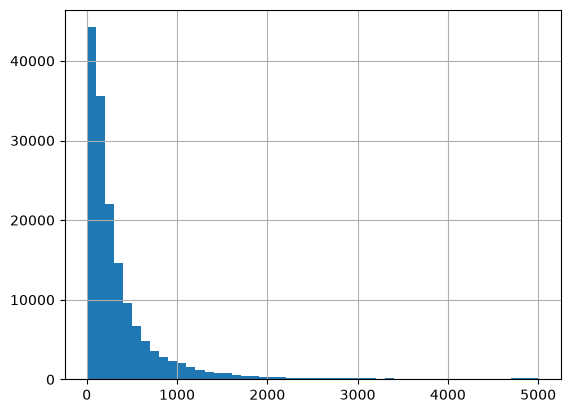

In [55]:
train_df['comment_text'].map(len).hist(bins=50)
plt.show()